# Classificació C vs I (Oz, 1000-1500 ms)

Flux net i directe:
- Dades EEG preprocessades en format .fif
- Finestra temporal de 1000 a 1500 ms
- Canal Oz
- Classes: Congruent (C) vs Incongruent (I = Pur + Mixt)
- Caracteristiques oscil.latories amb STFT (finestra 500 ms, pas 0.02 s) en banda alpha (8-12 Hz)
- Deteccio d'atipics amb distancia de Mahalanobis (sense eliminar-los)
- Classificacio amb PCA + LDA i validacio creuada

In [ ]:
import sys
from pathlib import Path

%pip install -q mne
import mne
import numpy as np
from matplotlib import pyplot as plt
from scipy.signal import stft
from scipy.stats import chi2
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score
import warnings

# Filtrem avisos coneguts no critics d'MNE
warnings.filterwarnings(
    "ignore",
    category=RuntimeWarning,
    module="mne",
    message=".*does not conform to MNE naming conventions.*",
)
warnings.filterwarnings(
    "ignore",
    category=UserWarning,
    module="sklearn.utils.validation",
    message=".*LGBMClassifier was fitted with feature names.*",
)
warnings.filterwarnings(
    "ignore",
    category=RuntimeWarning,
    module="mne",
    message=".*events passed to the Epochs constructor are not chronologically ordered.*",
)

mne.set_log_level("WARNING")

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    possible_paths = [
        Path("/content/drive/Shareddrives/TFG_Nils_2026"),
        Path("/content/drive/MyDrive/TFG_Nils_2026"),
    ]
    BASE_DIR = next((p for p in possible_paths if p.exists()), possible_paths[0])
    DATA_DIR = BASE_DIR / "02_Data" / "01_Preprocessed_epochs"
else:
    BASE_DIR = Path(".").resolve()
    DATA_DIR = BASE_DIR / "data"

TARGET_CH = "Oz"
K_FOLD = 5
TARGET_WINDOW = (1.0, 1.5)
ALPHA_FREQS = np.arange(8, 13, 1)
STFT_WIN_SEC = 0.5
STFT_STEP_SEC = 0.02
COND_EVENTS = {
    "Congruent": ["event_1", "event_2"],
    "Incongruent": ["event_3", "event_4", "event_5", "event_6", "event_7", "event_8"],
    "Incongruent Pur": ["event_3", "event_4", "event_5", "event_6"],
    "Incongruent Mixt": ["event_7", "event_8"]
}

fitxers = sorted(DATA_DIR.glob("*.fif"))
print(f"Entorn: {'Colab' if IN_COLAB else 'Local'}")
print(f"Directori dades: {DATA_DIR}")
print(f"Fitxers trobats: {len(fitxers)}")

Mounted at /content/drive
Entorn: Colab
Directori dades: /content/drive/MyDrive/TFG_Nils_2026/02_Data/01_Preprocessed_epochs
Fitxers trobats: 47


In [3]:
X_list, y_list, subj_list = [], [], []

for fif_path in fitxers:
    ep = mne.read_epochs(fif_path, preload=True, verbose=False)
    # Corregir unitats i tipus (surten com a 'misc' del preprocessat)
    for ch in ep.info["chs"]:
        ch["unit"] = mne.io.constants.FIFF.FIFF_UNIT_V
    ep.set_channel_types({ch: "eeg" for ch in ep.ch_names}, on_unit_change="ignore")

    if TARGET_CH not in ep.ch_names:
        print(f"Advertencia: {fif_path.name} no te el canal {TARGET_CH}. S'omet aquest fitxer.")
        continue

    ep = ep.copy().pick([TARGET_CH]).crop(tmin=TARGET_WINDOW[0], tmax=TARGET_WINDOW[1])
    c_names = [n for n in COND_EVENTS["Congruent"] if n in ep.event_id]
    i_names = [n for n in COND_EVENTS["Incongruent"] if n in ep.event_id]

    if not c_names or not i_names:
        continue

    selected_names = c_names + i_names
    ep_bin = ep[selected_names]
    c_codes = [ep.event_id[n] for n in c_names]
    y_subj = np.where(np.isin(ep_bin.events[:, 2], c_codes), 0, 1)

    x_data = ep_bin.get_data().astype(np.float32, copy=False)  # (n_epochs, 1, n_times)
    sfreq = ep_bin.info["sfreq"]
    nperseg = int(round(STFT_WIN_SEC * sfreq))
    hop = int(round(STFT_STEP_SEC * sfreq))
    noverlap = max(0, nperseg - hop)
    nfft = max(nperseg, int(round(sfreq)))

    f, t, Z = stft(
        x_data,
        fs=sfreq,
        window="hann",
        nperseg=nperseg,
        noverlap=noverlap,
        nfft=nfft,
        boundary="zeros",
        padded=True,
        axis=-1,
    )
    power = np.abs(Z) ** 2  # (n_epochs, 1, n_freq, n_t)

    freq_idx = np.array([np.argmin(np.abs(f - fr)) for fr in ALPHA_FREQS])
    power_sel = power[:, :, freq_idx, :]
    X_subj = power_sel.reshape(power_sel.shape[0], -1)

    X_list.append(X_subj)
    y_list.append(y_subj)
    subj_list.extend([fif_path.stem] * len(y_subj))

X = np.vstack(X_list)
y = np.concatenate(y_list)
subj_list = np.array(subj_list)

print(f"Mostres totals: {len(y)}")
print(f"Congruent (0): {(y == 0).sum()} | Incongruent (1): {(y == 1).sum()}")
print(f"Subjectes inclosos: {len(np.unique(subj_list))}")
print(f"Matriu de caracteristiques: {X.shape}")

Mostres totals: 22860
Congruent (0): 8471 | Incongruent (1): 14389
Subjectes inclosos: 47
Matriu de caracteristiques: (22860, 135)


Atipics detectats: 839 de 22860; (3.67%)
Nota: no els eliminem en aquesta versió.


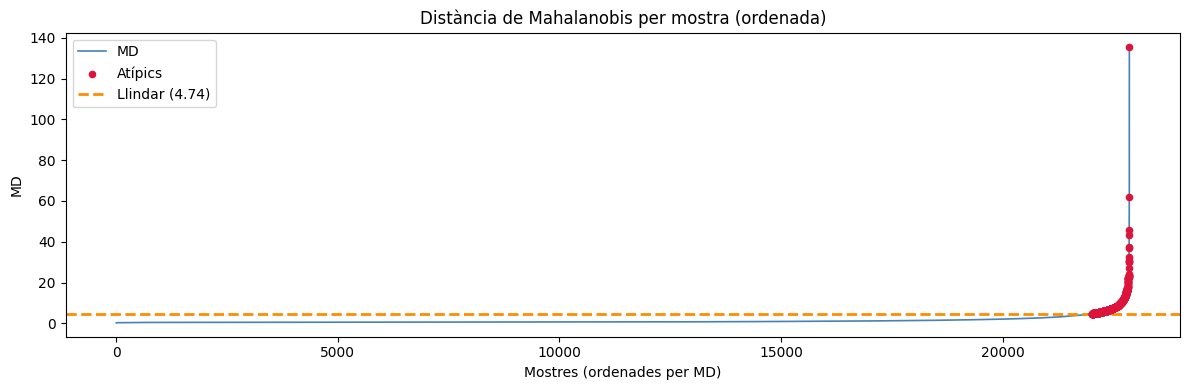

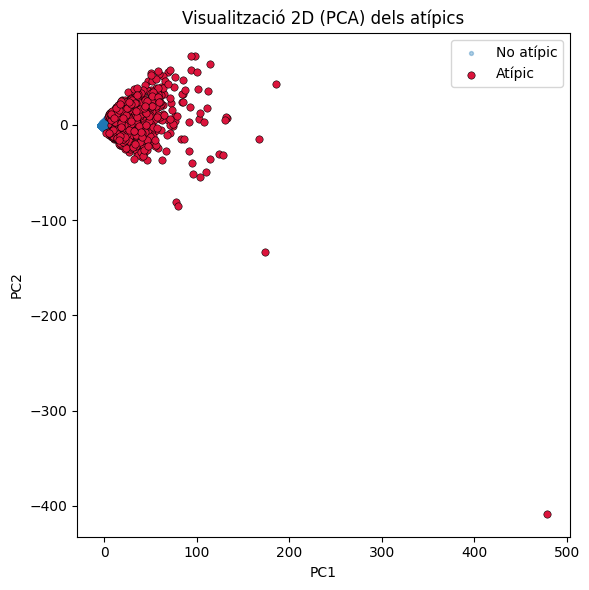

In [4]:
def mahalanobis_outliers(data, alpha=0.999):
    scaler = StandardScaler()
    data_scaled = scaler.fit_transform(data)

    pca_m = PCA(n_components=0.95, random_state=42)
    data_pca = pca_m.fit_transform(data_scaled)

    mean = np.mean(data_pca, axis=0)
    cov = np.cov(data_pca, rowvar=False)
    inv_cov = np.linalg.pinv(cov)

    diff = data_pca - mean
    md2 = np.einsum("ij,jk,ik->i", diff, inv_cov, diff)
    md = np.sqrt(np.clip(md2, 0, None))

    threshold = np.sqrt(chi2.ppf(alpha, df=data_pca.shape[1]))
    return md, md > threshold, threshold, data_pca


md_values, is_outlier, md_threshold, data_pca = mahalanobis_outliers(X)
print(f"Atipics detectats: {is_outlier.sum()} de {len(X)}; ({is_outlier.mean() * 100:.2f}%)")
print("Nota: no els eliminem en aquesta versió.")

# --- Plot 1: distància de Mahalanobis ordenada ---
order = np.argsort(md_values)
md_sorted = md_values[order]
out_sorted = is_outlier[order]

plt.figure(figsize=(12, 4))
plt.plot(md_sorted, color="steelblue", lw=1.2, label="MD")
plt.scatter(
    np.where(out_sorted)[0],
    md_sorted[out_sorted],
    color="crimson",
    s=20,
    label="Atípics",
    zorder=3,
)
plt.axhline(md_threshold, color="darkorange", ls="--", lw=2, label=f"Llindar ({md_threshold:.2f})")
plt.title("Distància de Mahalanobis per mostra (ordenada)")
plt.xlabel("Mostres (ordenades per MD)")
plt.ylabel("MD")
plt.legend()
plt.tight_layout()
plt.show()

# --- Plot 2: projecció PCA 2D amb atípics ---
plt.figure(figsize=(6, 6))
plt.scatter(
    data_pca[~is_outlier, 0],
    data_pca[~is_outlier, 1],
    s=8,
    alpha=0.35,
    label="No atípic",
)
plt.scatter(
    data_pca[is_outlier, 0],
    data_pca[is_outlier, 1],
    s=28,
    c="crimson",
    edgecolors="k",
    linewidths=0.4,
    label="Atípic",
)
plt.title("Visualització 2D (PCA) dels atípics")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.tight_layout()
plt.show()

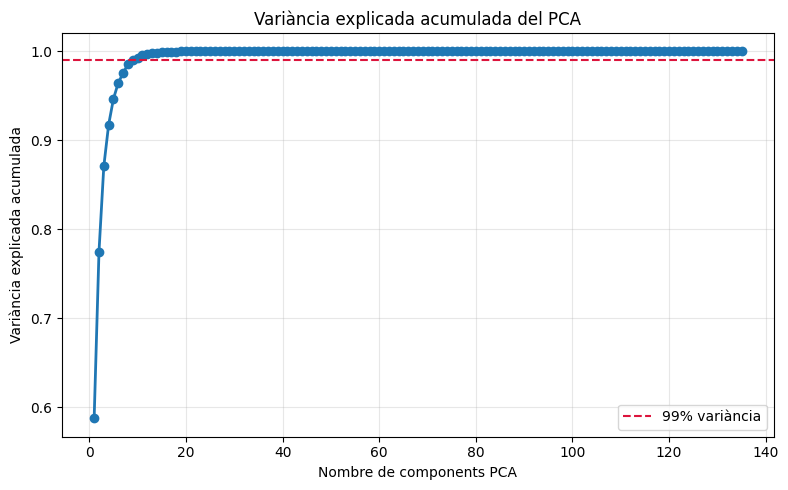

Components per 70% variància: 2
Components per 80% variància: 3
Components per 90% variància: 4
Components per 95% variància: 6
Components per 99% variància: 10
Components per 99.9% variància: 16


In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X_pca_source = X_trainval if "X_trainval" in globals() else X

X_scaled = StandardScaler().fit_transform(X_pca_source)
pca_full = PCA().fit(X_scaled)

cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_components = np.arange(1, len(cum_var) + 1)

plt.figure(figsize=(8, 5))
plt.plot(n_components, cum_var, marker="o", lw=2)
plt.axhline(0.99, color="crimson", ls="--", lw=1.5, label="99% variància")
plt.xlabel("Nombre de components PCA")
plt.ylabel("Variància explicada acumulada")
plt.title("Variància explicada acumulada del PCA")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Components per 70% variància: {np.searchsorted(cum_var, 0.70) + 1}")
print(f"Components per 80% variància: {np.searchsorted(cum_var, 0.80) + 1}")
print(f"Components per 90% variància: {np.searchsorted(cum_var, 0.90) + 1}")
print(f"Components per 95% variància: {np.searchsorted(cum_var, 0.95) + 1}")
print(f"Components per 99% variància: {np.searchsorted(cum_var, 0.99) + 1}")
print(f"Components per 99.9% variància: {np.searchsorted(cum_var, 0.999) + 1}")

In [6]:
from time import perf_counter
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_validate

# Metri ca objectiu principal del notebook
F1_SCORING = "f1_macro"

# --- Holdout final independent per subjecte (mai vist durant CV) ---
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
trainval_idx, test_idx_final = next(gss.split(X, y, groups=subj_list))

X_trainval, y_trainval = X[trainval_idx], y[trainval_idx]
X_test_final, y_test_final = X[test_idx_final], y[test_idx_final]
groups_trainval = subj_list[trainval_idx]
groups_test = subj_list[test_idx_final]

print("Separacio final train/val/test per subjecte:")
print(f"Subjectes train/val: {len(np.unique(groups_trainval))}")
print(f"Subjectes test final: {len(np.unique(groups_test))}")
print(f"Mostres train/val: {len(y_trainval)}")
print(f"Mostres test final: {len(y_test_final)}")

cv = StratifiedGroupKFold(n_splits=K_FOLD, shuffle=True, random_state=42)


def run_model_cv(
    model_name,
    pipeline,
    X_trainval,
    y_trainval,
    cv,
    groups_trainval,
    X_test_final,
    y_test_final,
):
    cv_splits = list(cv.split(X_trainval, y_trainval, groups=groups_trainval))

    t0 = perf_counter()
    cv_results = cross_validate(
        pipeline,
        X_trainval,
        y_trainval,
        cv=cv_splits,
        scoring={"f1_macro": "f1_macro", "accuracy": "accuracy"},
        n_jobs=-1,
        pre_dispatch="2*n_jobs",
        return_train_score=False,
    )
    elapsed = perf_counter() - t0

    f1_scores = cv_results["test_f1_macro"]
    acc_scores = cv_results["test_accuracy"]

    print(f"Resultats CV C vs I amb {model_name}:")
    print(f"F1 macro -> Mitjana: {f1_scores.mean():.3f} | Desviacio: {f1_scores.std():.3f}")
    print(f"Accuracy -> Mitjana: {acc_scores.mean():.3f} | Desviacio: {acc_scores.std():.3f}")
    print(f"Scores F1 macro per fold: {np.round(f1_scores, 3)}")
    print(f"Scores Accuracy per fold: {np.round(acc_scores, 3)}")
    print(f"Temps CV: {elapsed:.2f} s")

    # Diagnosi en l'ultim fold de CV
    train_idx, val_idx = cv_splits[-1]
    clf_last = clone(pipeline)
    clf_last.fit(X_trainval[train_idx], y_trainval[train_idx])
    y_pred_val = clf_last.predict(X_trainval[val_idx])

    print("\nDetall ultim fold de CV (per comprovar biaix de classe):")
    print("Confusion matrix [files=true, columnes=pred]:")
    print(confusion_matrix(y_trainval[val_idx], y_pred_val))
    print("Classification report:")
    print(
        classification_report(
            y_trainval[val_idx],
            y_pred_val,
            target_names=["Congruent (C)", "Incongruent (I)"],
            digits=3,
        )
    )

    # Entrenament final en train/val complet + test independent
    clf_final = clone(pipeline)
    clf_final.fit(X_trainval, y_trainval)
    y_pred_test = clf_final.predict(X_test_final)

    print("\nResultat en TEST FINAL independent (subjectes no vistos):")
    print("Confusion matrix [files=true, columnes=pred]:")
    print(confusion_matrix(y_test_final, y_pred_test))
    print("Classification report:")
    print(
        classification_report(
            y_test_final,
            y_pred_test,
            target_names=["Congruent (C)", "Incongruent (I)"],
            digits=3,
        )
    )

    return {
        "scores": f1_scores,
        "f1_macro_scores": f1_scores,
        "accuracy_scores": acc_scores,
        "elapsed": elapsed,
        "clf_final": clf_final,
        "y_pred_test": y_pred_test,
    }


lr_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.99, random_state=42)),
        (
            "lr",
            LogisticRegression(
                class_weight="balanced",
                max_iter=2000,
                random_state=42,
            ),
        ),
    ]
)

lr_result = run_model_cv(
    "Logistic Regression",
    lr_pipeline,
    X_trainval,
    y_trainval,
    cv,
    groups_trainval,
    X_test_final,
    y_test_final,
)
lr_scores = lr_result["f1_macro_scores"]

Separacio final train/val/test per subjecte:
Subjectes train/val: 37
Subjectes test final: 10
Mostres train/val: 17466
Mostres test final: 5394
Resultats CV C vs I amb Logistic Regression:
F1 macro -> Mitjana: 0.524 | Desviacio: 0.015
Accuracy -> Mitjana: 0.594 | Desviacio: 0.022
Scores F1 macro per fold: [0.51  0.533 0.549 0.517 0.512]
Scores Accuracy per fold: [0.598 0.594 0.599 0.557 0.625]
Temps CV: 4.31 s

Detall ultim fold de CV (per comprovar biaix de classe):
Confusion matrix [files=true, columnes=pred]:
[[ 235  905]
 [ 327 1818]]
Classification report:
                 precision    recall  f1-score   support

  Congruent (C)      0.418     0.206     0.276      1140
Incongruent (I)      0.668     0.848     0.747      2145

       accuracy                          0.625      3285
      macro avg      0.543     0.527     0.512      3285
   weighted avg      0.581     0.625     0.584      3285


Resultat en TEST FINAL independent (subjectes no vistos):
Confusion matrix [files=true

In [7]:
clf_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.99, random_state=42)),
        ("lda", LDA(priors=[0.5, 0.5], solver="svd")),
    ]
)

lda_result = run_model_cv(
    "LDA",
    clf_pipeline,
    X_trainval,
    y_trainval,
    cv,
    groups_trainval,
    X_test_final,
    y_test_final,
)

Resultats CV C vs I amb LDA:
F1 macro -> Mitjana: 0.524 | Desviacio: 0.017
Accuracy -> Mitjana: 0.598 | Desviacio: 0.020
Scores F1 macro per fold: [0.502 0.533 0.551 0.523 0.51 ]
Scores Accuracy per fold: [0.596 0.599 0.603 0.565 0.629]
Temps CV: 0.35 s

Detall ultim fold de CV (per comprovar biaix de classe):
Confusion matrix [files=true, columnes=pred]:
[[ 223  917]
 [ 302 1843]]
Classification report:
                 precision    recall  f1-score   support

  Congruent (C)      0.425     0.196     0.268      1140
Incongruent (I)      0.668     0.859     0.751      2145

       accuracy                          0.629      3285
      macro avg      0.546     0.527     0.510      3285
   weighted avg      0.583     0.629     0.584      3285


Resultat en TEST FINAL independent (subjectes no vistos):
Confusion matrix [files=true, columnes=pred]:
[[ 718 1313]
 [ 880 2483]]
Classification report:
                 precision    recall  f1-score   support

  Congruent (C)      0.449     0.3

In [8]:
# PCA en RF per reduir dimensionalitat i accelerar entrenament
rf_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.99, random_state=42)),
        (
            "rf",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=16,
                min_samples_leaf=3,
                class_weight="balanced_subsample",
                random_state=42,
                n_jobs=-1,
            ),
        ),
    ]
)

rf_result = run_model_cv(
    "Random Forest",
    rf_pipeline,
    X_trainval,
    y_trainval,
    cv,
    groups_trainval,
    X_test_final,
    y_test_final,
)

Resultats CV C vs I amb Random Forest:
F1 macro -> Mitjana: 0.499 | Desviacio: 0.009
Accuracy -> Mitjana: 0.606 | Desviacio: 0.012
Scores F1 macro per fold: [0.493 0.499 0.505 0.513 0.487]
Scores Accuracy per fold: [0.598 0.606 0.604 0.594 0.629]
Temps CV: 45.30 s

Detall ultim fold de CV (per comprovar biaix de classe):
Confusion matrix [files=true, columnes=pred]:
[[ 167  973]
 [ 250 1895]]
Classification report:
                 precision    recall  f1-score   support

  Congruent (C)      0.400     0.146     0.215      1140
Incongruent (I)      0.661     0.883     0.756      2145

       accuracy                          0.628      3285
      macro avg      0.531     0.515     0.485      3285
   weighted avg      0.570     0.628     0.568      3285


Resultat en TEST FINAL independent (subjectes no vistos):
Confusion matrix [files=true, columnes=pred]:
[[ 430 1601]
 [ 550 2813]]
Classification report:
                 precision    recall  f1-score   support

  Congruent (C)      0.

In [9]:
%pip install -q xgboost lightgbm

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

In [10]:
xgb_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.99, random_state=42)),
        (
            "xgb",
            XGBClassifier(
                n_estimators=220,
                max_depth=5,
                learning_rate=0.05,
                subsample=0.9,
                colsample_bytree=0.8,
                reg_lambda=1.0,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1,
            ),
        ),
    ]
)

xgb_result = run_model_cv(
    "XGBoost",
    xgb_pipeline,
    X_trainval,
    y_trainval,
    cv,
    groups_trainval,
    X_test_final,
    y_test_final,
)

Resultats CV C vs I amb XGBoost:
F1 macro -> Mitjana: 0.445 | Desviacio: 0.021
Accuracy -> Mitjana: 0.628 | Desviacio: 0.011
Scores F1 macro per fold: [0.44  0.42  0.474 0.466 0.424]
Scores Accuracy per fold: [0.631 0.622 0.627 0.614 0.646]
Temps CV: 1.97 s

Detall ultim fold de CV (per comprovar biaix de classe):
Confusion matrix [files=true, columnes=pred]:
[[  42 1098]
 [  65 2080]]
Classification report:
                 precision    recall  f1-score   support

  Congruent (C)      0.393     0.037     0.067      1140
Incongruent (I)      0.654     0.970     0.782      2145

       accuracy                          0.646      3285
      macro avg      0.524     0.503     0.424      3285
   weighted avg      0.564     0.646     0.534      3285


Resultat en TEST FINAL independent (subjectes no vistos):
Confusion matrix [files=true, columnes=pred]:
[[ 180 1851]
 [ 159 3204]]
Classification report:
                 precision    recall  f1-score   support

  Congruent (C)      0.531    

In [11]:
lgbm_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.80, random_state=42)),
        (
            "lgbm",
            LGBMClassifier(
                n_estimators=260,
                learning_rate=0.05,
                num_leaves=31,
                max_depth=-1,
                subsample=0.9,
                colsample_bytree=0.8,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1,
                verbose=-1,
            ),
        ),
    ]
)

lgbm_result = run_model_cv(
    "LightGBM",
    lgbm_pipeline,
    X_trainval,
    y_trainval,
    cv,
    groups_trainval,
    X_test_final,
    y_test_final,
)

Resultats CV C vs I amb LightGBM:
F1 macro -> Mitjana: 0.516 | Desviacio: 0.007
Accuracy -> Mitjana: 0.544 | Desviacio: 0.012
Scores F1 macro per fold: [0.512 0.513 0.53  0.512 0.513]
Scores Accuracy per fold: [0.536 0.536 0.555 0.532 0.562]
Temps CV: 5.73 s


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Detall ultim fold de CV (per comprovar biaix de classe):
Confusion matrix [files=true, columnes=pred]:
[[ 401  739]
 [ 699 1446]]
Classification report:
                 precision    recall  f1-score   support

  Congruent (C)      0.365     0.352     0.358      1140
Incongruent (I)      0.662     0.674     0.668      2145

       accuracy                          0.562      3285
      macro avg      0.513     0.513     0.513      3285
   weighted avg      0.559     0.562     0.560      3285


Resultat en TEST FINAL independent (subjectes no vistos):
Confusion matrix [files=true, columnes=pred]:
[[ 913 1118]
 [1340 2023]]
Classification report:
                 precision    recall  f1-score   support

  Congruent (C)      0.405     0.450     0.426      2031
Incongruent (I)      0.644     0.602     0.622      3363

       accuracy                          0.544      5394
      macro avg      0.525     0.526     0.524      5394
   weighted avg      0.554     0.544     0.548      5394



/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [12]:
def mean_f1(res):
    return np.mean(res["f1_macro_scores"]) if "f1_macro_scores" in res else np.mean(res["scores"])


def mean_acc(res):
    return np.mean(res["accuracy_scores"]) if "accuracy_scores" in res else float("nan")


print("Comparativa CV (F1 macro | Accuracy):")
print(f"LR: {mean_f1(lr_result):.3f} | {mean_acc(lr_result):.3f}")
print(f"LDA: {mean_f1(lda_result):.3f} | {mean_acc(lda_result):.3f}")
print(f"RF: {mean_f1(rf_result):.3f} | {mean_acc(rf_result):.3f}")
print(f"XGBoost: {mean_f1(xgb_result):.3f} | {mean_acc(xgb_result):.3f}")
print(f"LightGBM: {mean_f1(lgbm_result):.3f} | {mean_acc(lgbm_result):.3f}")

Comparativa CV (F1 macro | Accuracy):
LR: 0.524 | 0.594
LDA: 0.524 | 0.598
RF: 0.499 | 0.606
XGBoost: 0.445 | 0.628
LightGBM: 0.516 | 0.544


# Percentatge de variància acumulada del PCA (70%, 80%, 90%, 99%) + NO PCA

Aquesta secció entrena **5 models** per a cada configuració:
- PCA 0.70
- PCA 0.80
- PCA 0.90
- PCA 0.99
- PCA 0.999
- NO PCA (al final, separat)

Es reporten mètriques de CV i de test final independent per comparar de forma homogènia i més interpretable.

In [33]:
from sklearn.metrics import accuracy_score

PCA_LEVELS = [0.70, 0.80, 0.90, 0.99, 0.999]
EXPERIMENTS = [{"label": f"PCA {lvl:.3f}", "use_pca": True, "pca_level": lvl} for lvl in PCA_LEVELS] + [
    {"label": "NO PCA", "use_pca": False, "pca_level": None}
]

# Pes per XGBoost: com que la classe 1 és majoritària, la reduïm una mica.
pos_weight = (y_trainval == 0).sum() / (y_trainval == 1).sum()


def make_pca_step(use_pca, level):
    if not use_pca:
        return "passthrough"
    return PCA(n_components=level, random_state=42)


def build_model_pipeline(model_name, use_pca, pca_level=None):
    pca_step = make_pca_step(use_pca, pca_level)

    if model_name == "LR":
        est = LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42)
    elif model_name == "LDA":
        est = LDA(priors=[0.5, 0.5], solver="svd")
    elif model_name == "RF":
        est = RandomForestClassifier(
            n_estimators=200,
            max_depth=16,
            min_samples_leaf=3,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1,
        )
    elif model_name == "XGB":
        est = XGBClassifier(
            n_estimators=350,
            max_depth=4,
            learning_rate=0.03,
            subsample=0.9,
            colsample_bytree=0.8,
            reg_lambda=2.0,
            min_child_weight=3,
            gamma=0.1,
            scale_pos_weight=pos_weight,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1,
        )
    elif model_name == "LGBM":
        est = LGBMClassifier(
            n_estimators=260,
            learning_rate=0.05,
            num_leaves=31,
            max_depth=-1,
            subsample=0.9,
            colsample_bytree=0.8,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1,
            verbose=-1,
        )
    else:
        raise ValueError(f"Model desconegut: {model_name}")

    return Pipeline(
        [
            ("scaler", StandardScaler()),
            ("pca", pca_step),
            ("model", est),
        ]
    )


def evaluate_pipeline_compact(pipeline, cv_splits):
    cv_results = cross_validate(
        pipeline,
        X_trainval,
        y_trainval,
        cv=cv_splits,
        scoring={"f1_macro": "f1_macro", "accuracy": "accuracy"},
        n_jobs=-1,
        pre_dispatch="2*n_jobs",
        return_train_score=False,
    )

    f1_cv = cv_results["test_f1_macro"]
    acc_cv = cv_results["test_accuracy"]

    clf = clone(pipeline)
    clf.fit(X_trainval, y_trainval)
    y_pred_test = clf.predict(X_test_final)

    f1_c = f1_score(y_test_final, y_pred_test, labels=[0], average=None)[0]
    f1_i = f1_score(y_test_final, y_pred_test, labels=[1], average=None)[0]

    return {
        "f1_cv_mean": float(np.mean(f1_cv)),
        "f1_cv_std": float(np.std(f1_cv)),
        "acc_cv_mean": float(np.mean(acc_cv)),
        "acc_cv_std": float(np.std(acc_cv)),
        "f1_test_macro": float(f1_score(y_test_final, y_pred_test, average="macro")),
        "acc_test": float(accuracy_score(y_test_final, y_pred_test)),
        "f1_c_test": float(f1_c),
        "f1_i_test": float(f1_i),
        "f1_product_test": float(f1_c * f1_i),
    }


cv_splits_fixed = list(cv.split(X_trainval, y_trainval, groups=groups_trainval))
model_names = ["LR", "LDA", "RF", "XGB", "LGBM"]

print(f"Pos weight XGB (classe 1): {pos_weight:.3f}")
print("Refactoritzacio preparada: PCA 0.70/0.80/0.90/0.99/0.999 + NO PCA final.")

Pos weight XGB (classe 1): 0.584
Refactoritzacio preparada: PCA 0.70/0.80/0.90/0.99/0.999 + NO PCA final.


In [35]:
all_results = []

for exp in EXPERIMENTS:
    label = exp["label"]
    use_pca = exp["use_pca"]
    pca_level = exp["pca_level"]

    print("\n" + "=" * 110)
    print(f"Configuració: {label}")
    print("=" * 110)

    for model_name in model_names:
        pipeline = build_model_pipeline(model_name, use_pca=use_pca, pca_level=pca_level)
        metrics = evaluate_pipeline_compact(pipeline, cv_splits_fixed)
        row = {
            "setting": label,
            "use_pca": use_pca,
            "pca_level": pca_level,
            "model": model_name,
            **metrics,
        }
        all_results.append(row)

        print(
            f"{model_name:>4} | "
            f"CV F1={metrics['f1_cv_mean']:.3f}+/-{metrics['f1_cv_std']:.3f} | "
            f"CV ACC={metrics['acc_cv_mean']:.3f}+/-{metrics['acc_cv_std']:.3f} | "
            f"TEST F1={metrics['f1_test_macro']:.3f} | "
            f"TEST ACC={metrics['acc_test']:.3f} | "
            f"F1_C={metrics['f1_c_test']:.3f} | F1_I={metrics['f1_i_test']:.3f} | "
            f"F1_C*F1_I={metrics['f1_product_test']:.3f}"
        )

print("\n" + "#" * 130)
print("RÀNQUING GLOBAL (ordenat per TEST F1 macro i despres PRODUCTE F1)")
print("#" * 130)

all_results_sorted = sorted(
    all_results,
    key=lambda r: (r["f1_test_macro"], r["f1_product_test"], r["acc_test"]),
    reverse=True,
)

print("SETTING  | MODEL | TEST_F1 | TEST_ACC | F1_C | F1_I | PROD_F1 | CV_F1")
print("-" * 130)
for r in all_results_sorted:
    print(
        f"{r['setting']:<8} | {r['model']:>5} | {r['f1_test_macro']:.3f}   | {r['acc_test']:.3f}    | "
        f"{r['f1_c_test']:.3f} | {r['f1_i_test']:.3f} | {r['f1_product_test']:.3f}   | {r['f1_cv_mean']:.3f}"
    )

print("\n" + "#" * 130)
print("MILLOR MODEL PER CADA CONFIGURACIÓ (segons TEST F1 macro)")
print("#" * 130)
for exp in EXPERIMENTS:
    label = exp["label"]
    subset = [r for r in all_results if r["setting"] == label]
    best = sorted(subset, key=lambda r: (r["f1_test_macro"], r["f1_product_test"]), reverse=True)[0]
    print(
        f"{label}: {best['model']} | TEST F1={best['f1_test_macro']:.3f} | "
        f"ACC={best['acc_test']:.3f} | F1_C={best['f1_c_test']:.3f} | F1_I={best['f1_i_test']:.3f}"
    )


Configuració: PCA 0.700
  LR | CV F1=0.524+/-0.015 | CV ACC=0.600+/-0.024 | TEST F1=0.544 | TEST ACC=0.595 | F1_C=0.391 | F1_I=0.697 | F1_C*F1_I=0.272
 LDA | CV F1=0.522+/-0.019 | CV ACC=0.603+/-0.023 | TEST F1=0.540 | TEST ACC=0.595 | F1_C=0.380 | F1_I=0.699 | F1_C*F1_I=0.266
  RF | CV F1=0.517+/-0.006 | CV ACC=0.579+/-0.014 | TEST F1=0.517 | TEST ACC=0.568 | F1_C=0.362 | F1_I=0.673 | F1_C*F1_I=0.243
 XGB | CV F1=0.523+/-0.006 | CV ACC=0.553+/-0.005 | TEST F1=0.544 | TEST ACC=0.566 | F1_C=0.445 | F1_I=0.643 | F1_C*F1_I=0.286


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LGBM | CV F1=0.514+/-0.006 | CV ACC=0.533+/-0.005 | TEST F1=0.524 | TEST ACC=0.537 | F1_C=0.445 | F1_I=0.603 | F1_C*F1_I=0.268

Configuració: PCA 0.800
  LR | CV F1=0.522+/-0.015 | CV ACC=0.598+/-0.022 | TEST F1=0.546 | TEST ACC=0.593 | F1_C=0.398 | F1_I=0.693 | F1_C*F1_I=0.276
 LDA | CV F1=0.520+/-0.018 | CV ACC=0.600+/-0.021 | TEST F1=0.544 | TEST ACC=0.596 | F1_C=0.389 | F1_I=0.698 | F1_C*F1_I=0.272
  RF | CV F1=0.507+/-0.006 | CV ACC=0.585+/-0.016 | TEST F1=0.513 | TEST ACC=0.577 | F1_C=0.336 | F1_I=0.690 | F1_C*F1_I=0.232
 XGB | CV F1=0.521+/-0.009 | CV ACC=0.554+/-0.010 | TEST F1=0.528 | TEST ACC=0.552 | F1_C=0.421 | F1_I=0.634 | F1_C*F1_I=0.267


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LGBM | CV F1=0.516+/-0.007 | CV ACC=0.544+/-0.012 | TEST F1=0.524 | TEST ACC=0.544 | F1_C=0.426 | F1_I=0.622 | F1_C*F1_I=0.265

Configuració: PCA 0.900
  LR | CV F1=0.523+/-0.017 | CV ACC=0.598+/-0.022 | TEST F1=0.544 | TEST ACC=0.592 | F1_C=0.397 | F1_I=0.692 | F1_C*F1_I=0.275
 LDA | CV F1=0.522+/-0.017 | CV ACC=0.600+/-0.022 | TEST F1=0.545 | TEST ACC=0.597 | F1_C=0.392 | F1_I=0.699 | F1_C*F1_I=0.274
  RF | CV F1=0.500+/-0.010 | CV ACC=0.583+/-0.015 | TEST F1=0.517 | TEST ACC=0.585 | F1_C=0.335 | F1_I=0.699 | F1_C*F1_I=0.234
 XGB | CV F1=0.522+/-0.008 | CV ACC=0.555+/-0.014 | TEST F1=0.525 | TEST ACC=0.549 | F1_C=0.418 | F1_I=0.631 | F1_C*F1_I=0.264


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


... (2 outputs left out)

LGBM | CV F1=0.515+/-0.011 | CV ACC=0.553+/-0.016 | TEST F1=0.527 | TEST ACC=0.558 | F1_C=0.406 | F1_I=0.648 | F1_C*F1_I=0.263

Configuració: PCA 0.999
  LR | CV F1=0.522+/-0.011 | CV ACC=0.592+/-0.021 | TEST F1=0.543 | TEST ACC=0.589 | F1_C=0.397 | F1_I=0.688 | F1_C*F1_I=0.273
 LDA | CV F1=0.521+/-0.013 | CV ACC=0.596+/-0.023 | TEST F1=0.547 | TEST ACC=0.598 | F1_C=0.395 | F1_I=0.699 | F1_C*F1_I=0.276
  RF | CV F1=0.491+/-0.016 | CV ACC=0.616+/-0.010 | TEST F1=0.499 | TEST ACC=0.611 | F1_C=0.262 | F1_I=0.736 | F1_C*F1_I=0.193
 XGB | CV F1=0.518+/-0.007 | CV ACC=0.558+/-0.014 | TEST F1=0.539 | TEST ACC=0.571 | F1_C=0.419 | F1_I=0.660 | F1_C*F1_I=0.276


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LGBM | CV F1=0.514+/-0.004 | CV ACC=0.556+/-0.014 | TEST F1=0.525 | TEST ACC=0.560 | F1_C=0.394 | F1_I=0.655 | F1_C*F1_I=0.258

Configuració: NO PCA
  LR | CV F1=0.518+/-0.011 | CV ACC=0.584+/-0.017 | TEST F1=0.530 | TEST ACC=0.574 | F1_C=0.386 | F1_I=0.674 | F1_C*F1_I=0.260
 LDA | CV F1=0.521+/-0.007 | CV ACC=0.569+/-0.011 | TEST F1=0.529 | TEST ACC=0.562 | F1_C=0.405 | F1_I=0.653 | F1_C*F1_I=0.265
  RF | CV F1=0.489+/-0.014 | CV ACC=0.614+/-0.010 | TEST F1=0.491 | TEST ACC=0.604 | F1_C=0.251 | F1_I=0.731 | F1_C*F1_I=0.184
 XGB | CV F1=0.523+/-0.007 | CV ACC=0.551+/-0.014 | TEST F1=0.530 | TEST ACC=0.548 | F1_C=0.438 | F1_I=0.622 | F1_C*F1_I=0.273
LGBM | CV F1=0.516+/-0.008 | CV ACC=0.554+/-0.011 | TEST F1=0.527 | TEST ACC=0.553 | F1_C=0.417 | F1_I=0.637 | F1_C*F1_I=0.266

##################################################################################################################################
RÀNQUING GLOBAL (ordenat per TEST F1 macro i despres PRODUCTE F1)
##################

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
